# Laboratorio 9 · Entrega final — Visualización estática
**CC3084 Data Science · Universidad del Valle de Guatemala · 2026**  
**Autores:** Osman de León y Milton Polanco

Este notebook documenta la generación de los indicadores, el análisis temporal, la comparación de modelos bajo **un mismo corte temporal** y el pronóstico con intervalo del 80 %. Los resultados del Laboratorio 1 se distinguen de los resultados recalculados. Los datos tienen **uso académico, no son cifras oficiales publicadas**.

**Ejecución:** guardar el Excel en `data/raw/Base_Migracion_2009-2026jun.xlsx` y ejecutar desde `notebooks/`. Se crean CSV y figuras en `data/processed/` y `reporte/figuras/`. `prophet` es opcional: si no está instalado se documenta su omisión.

In [1]:
# Dependencias: pandas numpy matplotlib openpyxl statsmodels scikit-learn; opcional: prophet
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
warnings.filterwarnings('ignore', category=UserWarning)
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
RAW = ROOT / 'data' / 'raw' / 'Base_Migracion_2009-2026jun.xlsx'
PROCESSED = ROOT / 'data' / 'processed'
FIGURES = ROOT / 'reporte' / 'figuras'
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
assert RAW.exists(), f'Coloca la base original en: {RAW}'
NAVY, TEAL, ORANGE = '#17354c', '#087e8b', '#ef9950'
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Preparación y validación de la base

In [2]:
df = pd.read_excel(RAW, sheet_name='Datos')
required = ['Tipo de Viajero', 'Año', 'Mes cod', 'Viajero', 'Región dos', 'País', 'Vía']
assert set(required).issubset(df.columns), f'Faltan columnas: {set(required)-set(df.columns)}'
df = df.loc[df['Tipo de Viajero'].isin(['Turista','Excursionista'])].copy()
df['fecha'] = pd.to_datetime(dict(year=df['Año'], month=df['Mes cod'], day=1))
serie = df.groupby('fecha')['Viajero'].sum().sort_index().asfreq('MS')
assert serie.notna().all() and len(serie) == 210, 'Revisar meses ausentes o fechas inesperadas'
serie.name = 'viajeros'
serie.to_csv(PROCESSED / 'serie_mensual_verificada.csv', index_label='fecha')
print(f'{len(df):,} registros filtrados; {len(serie)} meses; total {serie.sum():,.2f}')
print(f'Cobertura: {serie.index.min():%Y-%m} a {serie.index.max():%Y-%m}')
print('Advertencia: si la columna Viajero contiene decimales, conservar la precisión de origen; no redondear silenciosamente.')

137,642 registros filtrados; 210 meses; total 46,711,912.89
Cobertura: 2009-01 a 2026-06
Advertencia: si la columna Viajero contiene decimales, conservar la precisión de origen; no redondear silenciosamente.


## 2. Titular y KPIs · panorama histórico

,Indicador,Valor
0,Total acumulado,46.71 millones
1,Meses observados,210
2,Vía predominante,Terrestre
3,Región predominante,América Del Centro


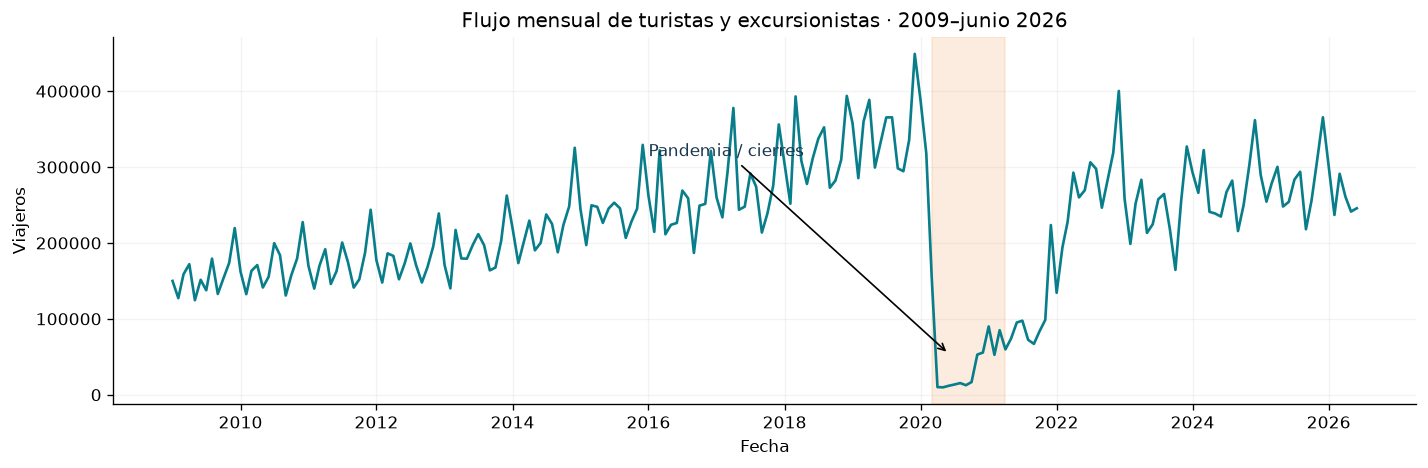

In [3]:
via = df.groupby('Vía')['Viajero'].sum().sort_values(ascending=False)
region = df.groupby('Región dos')['Viajero'].sum().sort_values(ascending=False)
meses = serie.groupby(serie.index.month).mean()
kpis = pd.DataFrame({'Indicador':['Total acumulado','Meses observados','Vía predominante','Región predominante'], 'Valor':[f'{serie.sum()/1e6:.2f} millones', str(len(serie)), str(via.index[0]), str(region.index[0])]})
display(kpis)
fig,ax=plt.subplots(figsize=(12,4)); ax.plot(serie.index,serie.values,color=TEAL,lw=1.6)
ax.axvspan(pd.Timestamp('2020-03-01'),pd.Timestamp('2021-04-01'),color=ORANGE,alpha=.18)
ax.annotate('Pandemia / cierres',xy=(pd.Timestamp('2020-06-01'),serie.max()*.12),xytext=(pd.Timestamp('2016-01-01'),serie.max()*.70),arrowprops={'arrowstyle':'->'},color=NAVY)
ax.set(title='Flujo mensual de turistas y excursionistas · 2009–junio 2026',ylabel='Viajeros',xlabel='Fecha');ax.grid(alpha=.15)
fig.tight_layout();fig.savefig(FIGURES/'final_01_historico.png');plt.show()

## 3. Estacionalidad, mercados y vías de ingreso

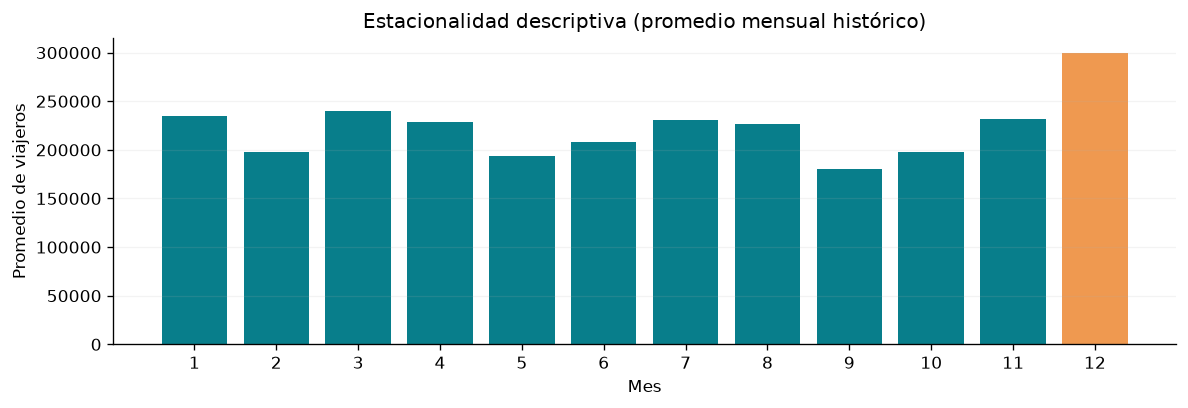

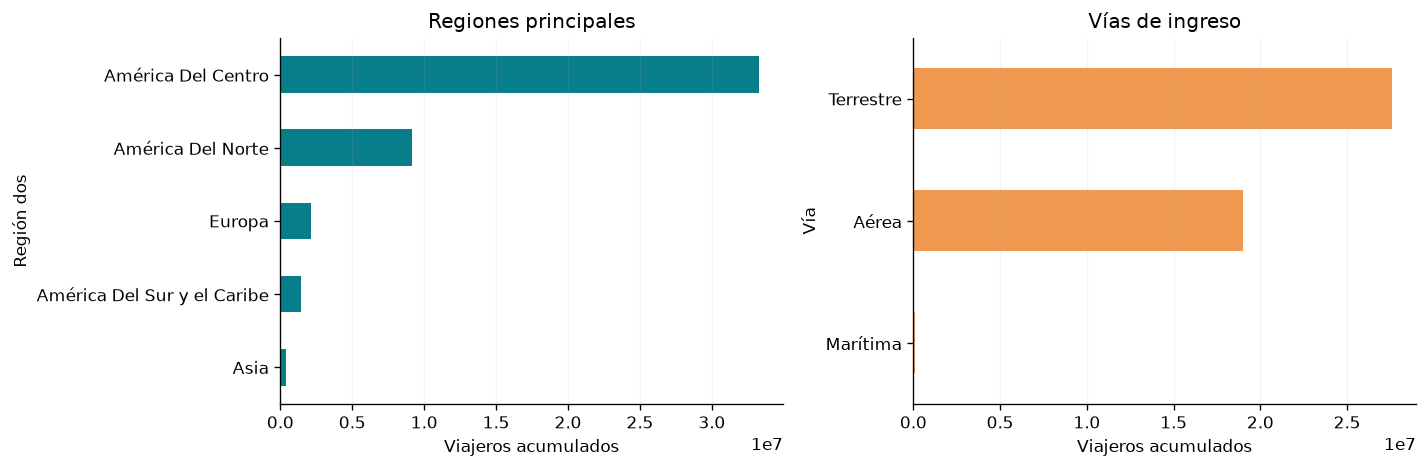

Los picos se asocian en el informe Lab 1 a Semana Santa, agosto y diciembre; asociación descriptiva, no causal.


In [4]:
fig,ax=plt.subplots(figsize=(10,3.5)); ax.bar(range(1,13),meses.values,color=[ORANGE if i==meses.idxmax() else TEAL for i in range(1,13)])
ax.set(xticks=range(1,13),xlabel='Mes',ylabel='Promedio de viajeros',title='Estacionalidad descriptiva (promedio mensual histórico)');ax.grid(axis='y',alpha=.15)
fig.tight_layout();fig.savefig(FIGURES/'final_02_estacionalidad.png');plt.show()
fig,axs=plt.subplots(1,2,figsize=(12,4));region.head(5).sort_values().plot.barh(ax=axs[0],color=TEAL,title='Regiones principales');via.sort_values().plot.barh(ax=axs[1],color=ORANGE,title='Vías de ingreso')
for ax in axs:ax.set_xlabel('Viajeros acumulados');ax.grid(axis='x',alpha=.15)
fig.tight_layout();fig.savefig(FIGURES/'final_03_mercados_vias.png');plt.show()
print('Los picos se asocian en el informe Lab 1 a Semana Santa, agosto y diciembre; asociación descriptiva, no causal.')

## 4. Comparación de las siete series y estacionariedad

In [5]:
series = {'Total':serie,
 'América del Centro':df.loc[df['Región dos']=='América Del Centro'].groupby('fecha')['Viajero'].sum().reindex(serie.index,fill_value=0),
 'América del Norte':df.loc[df['Región dos']=='América Del Norte'].groupby('fecha')['Viajero'].sum().reindex(serie.index,fill_value=0),
 'Europa':df.loc[df['Región dos']=='Europa'].groupby('fecha')['Viajero'].sum().reindex(serie.index,fill_value=0),
 'El Salvador':df.loc[df['País']=='El Salvador'].groupby('fecha')['Viajero'].sum().reindex(serie.index,fill_value=0),
 'Guatemala':df.loc[df['País']=='Guatemala'].groupby('fecha')['Viajero'].sum().reindex(serie.index,fill_value=0),
 'Estados Unidos':df.loc[df['País']=='Estados Unidos de América'].groupby('fecha')['Viajero'].sum().reindex(serie.index,fill_value=0)}
summary=[]
for name,s in series.items():
 pre=s.loc[:'2019-12'];pand=s.loc['2020']; base=s.loc['2019'];
 summary.append({'Serie':name,'Promedio mensual':s.mean(),'CV mensual':s.std()/s.mean() if s.mean() else np.nan,
                 'Cambio 2020 vs 2019 (%)':(pand.sum()/base.sum()-1)*100 if base.sum() else np.nan,
                 'ADF p (train)':adfuller(s.loc[:'2023-12'])[1]})
cuadrante=pd.DataFrame(summary);display(cuadrante.round(3));cuadrante.to_csv(PROCESSED/'final_comparacion_series.csv',index=False)
print('Cuidado: CV mensual, caída 2020 y ADF son medidas distintas; no equivalen al CV de residuos del informe Lab 1.')

C:\Users\Emadlg\AppData\Local\Temp\ipykernel_28892\607208289.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF p (train)':adfuller(s.loc[:'2023-12'])[1]})
C:\Users\Emadlg\AppData\Local\Temp\ipykernel_28892\607208289.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF p (train)':adfuller(s.loc[:'2023-12'])[1]})
C:\Users\Emadlg\AppData\Local\Temp\ipykernel_288

,Serie,Promedio mensual,CV mensual,Cambio 2020 vs 2019 (%),ADF p (train)
0,Total,222437.680,0.381,-74.354,0.057
1,América del Centro,158494.914,0.419,-74.431,0.029
2,América del Norte,43622.905,0.410,-74.144,0.030
3,Europa,10234.624,0.430,-71.830,0.004
4,El Salvador,67043.504,0.585,-79.779,0.154
5,Guatemala,66049.483,0.724,-70.191,0.273
6,Estados Unidos,33169.903,0.463,-73.991,0.075


Cuidado: CV mensual, caída 2020 y ADF son medidas distintas; no equivalen al CV de residuos del informe Lab 1.


## 5. Evaluación homogénea de modelos (serie total)
Se utiliza el corte **entrenamiento: enero 2009–diciembre 2023** y **prueba: enero 2024–junio 2026** para todos los modelos. Esta evaluación **no es directamente comparable** con el corte 70/30 del informe original. El ganador se elige por RMSE de prueba, no por AIC/BIC.

In [6]:
train=serie.loc[:'2023-12'];test=serie.loc['2024-01':]
assert len(test)==30
preds={}; fits={}; errores={}
def registrar(nombre,fn):
 try:
  p,fit=fn(); preds[nombre]=pd.Series(np.asarray(p,dtype=float),index=test.index);fits[nombre]=fit
 except Exception as e: errores[nombre]=f'{type(e).__name__}: {e}'
def sarima():
 fit=SARIMAX(train,order=(1,1,1),seasonal_order=(1,1,1,12),enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=120)
 return fit.get_forecast(steps=len(test)).predicted_mean,fit
registrar('SARIMA (1,1,1)(1,1,1,12)',sarima)
registrar('Holt-Winters',lambda: (lambda fit:(fit.forecast(len(test)),fit))(ExponentialSmoothing(train,trend='add',seasonal='add',seasonal_periods=12).fit()))
registrar('SES',lambda: (lambda fit:(fit.forecast(len(test)),fit))(SimpleExpSmoothing(train).fit()))
registrar('Seasonal Naive',lambda: (np.tile(train.iloc[-12:].values,int(np.ceil(len(test)/12)))[:len(test)],None))
try:
 from prophet import Prophet
 def prophet_pred():
  model=Prophet(yearly_seasonality=True,weekly_seasonality=False,daily_seasonality=False)
  model.fit(pd.DataFrame({'ds':train.index,'y':train.values}))
  p=model.predict(pd.DataFrame({'ds':test.index}))['yhat'].values
  return p,model
 registrar('Prophet',prophet_pred)
except ImportError: errores['Prophet']='No instalado: pip install prophet'
metricas=pd.DataFrame([{'Modelo':name,'MAE':mean_absolute_error(test,p),'RMSE':np.sqrt(mean_squared_error(test,p)),'AIC':getattr(fits[name],'aic',np.nan) if name.startswith('SARIMA') else np.nan,'BIC':getattr(fits[name],'bic',np.nan) if name.startswith('SARIMA') else np.nan} for name,p in preds.items()]).sort_values('RMSE').reset_index(drop=True)
display(metricas.round(2));print('Omisiones/fallos:',errores)
metricas.to_csv(PROCESSED/'final_metricas_modelos.csv',index=False)
assert len(metricas)>=4,'No se pudo evaluar suficientes modelos'
print('Mejor entre los modelos ejecutados:',metricas.iloc[0]['Modelo'])

Importing plotly failed. Interactive plots will not work.
22:20:50 - cmdstanpy - INFO - Chain [1] start processing
22:20:51 - cmdstanpy - INFO - Chain [1] done processing


,Modelo,MAE,RMSE,AIC,BIC
0,"SARIMA (1,1,1)(1,1,1,12)",16938.41,20990.04,3713.79,3728.94
1,Seasonal Naive,35776.97,41765.21,NaN,NaN
2,Holt-Winters,40404.16,45094.08,NaN,NaN
3,Prophet,51618.47,54294.12,NaN,NaN


Omisiones/fallos: {'SES': 'TypeError: initialization_method must be a string'}
Mejor entre los modelos ejecutados: SARIMA (1,1,1)(1,1,1,12)


## 6. Pronóstico del modelo ganador e intervalo de estimación 80 %
Los intervalos del modelo se calculan con su distribución predictiva cuando está disponible. Para modelos sin intervalo nativo se utiliza una **aproximación empírica** basada en residuos de entrenamiento (no garantiza cobertura del 80 %). Esta limitación se indica expresamente.

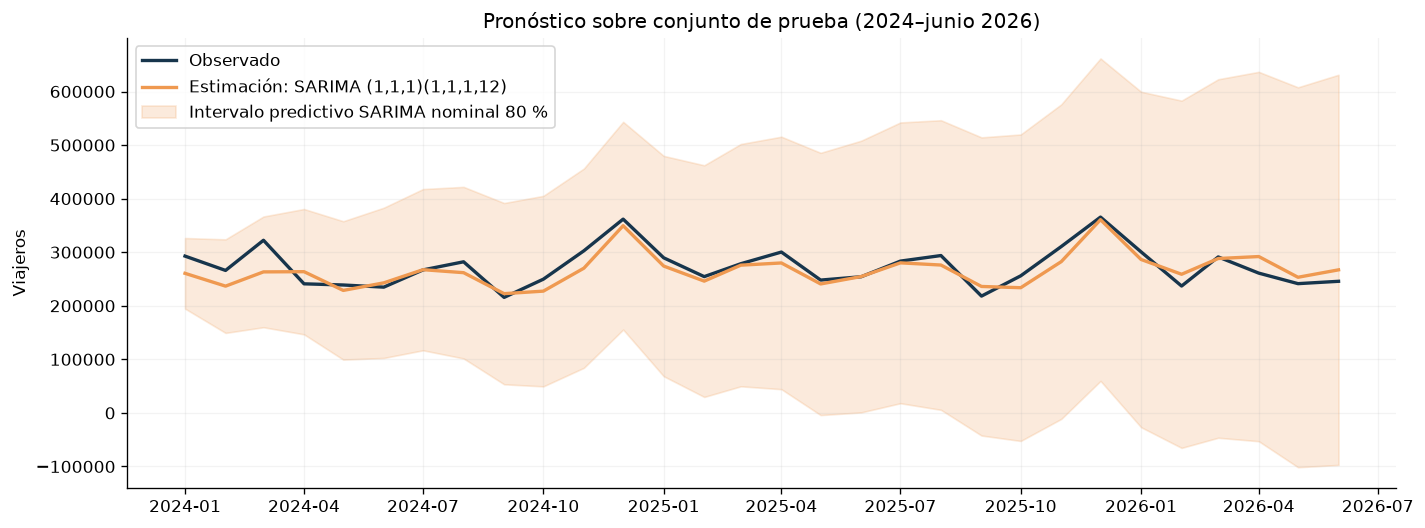

Intervalo predictivo SARIMA nominal 80 %


In [7]:
winner=metricas.iloc[0]['Modelo']; estimate=preds[winner]
if winner.startswith('SARIMA'):
 interval=fits[winner].get_forecast(steps=len(test)).conf_int(alpha=.20)
 low=interval.iloc[:,0].to_numpy();high=interval.iloc[:,1].to_numpy();method='Intervalo predictivo SARIMA nominal 80 %'
elif winner=='Prophet':
 p=fits[winner].predict(pd.DataFrame({'ds':test.index}))
 # Prophet por defecto produce un intervalo de 80%; se establece explícitamente en el ajuste si se modifica.
 low=p['yhat_lower'].to_numpy();high=p['yhat_upper'].to_numpy();method='Intervalo predictivo Prophet nominal 80 % (aproximado)'
else:
 fit=fits[winner]
 if winner=='Seasonal Naive':resid=train.iloc[12:].values-train.iloc[:-12].values
 else:resid=np.asarray(getattr(fit,'resid',train.diff().dropna()),dtype=float)
 resid=resid[np.isfinite(resid)];q=np.quantile(resid,[.10,.90]);low=estimate.values+q[0];high=estimate.values+q[1]
 method='Banda empírica de residuos 10–90 %; cobertura predictiva no validada'
pron=pd.DataFrame({'observado':test,'estimacion':estimate,'limite_inferior_80':low,'limite_superior_80':high})
pron.to_csv(PROCESSED/'final_pronostico_prueba_intervalo80.csv',index_label='fecha')
fig,ax=plt.subplots(figsize=(12,4.5));ax.plot(test.index,test.values,label='Observado',color=NAVY,lw=2);ax.plot(test.index,estimate.values,label=f'Estimación: {winner}',color=ORANGE,lw=2)
ax.fill_between(test.index,low,high,color=ORANGE,alpha=.2,label=method)
ax.set(title='Pronóstico sobre conjunto de prueba (2024–junio 2026)',ylabel='Viajeros');ax.legend();ax.grid(alpha=.15)
fig.tight_layout();fig.savefig(FIGURES/'final_04_pronostico_intervalo.png');plt.show()
print(method)

## 7. Comparativa visual y recomendaciones para INGUAT

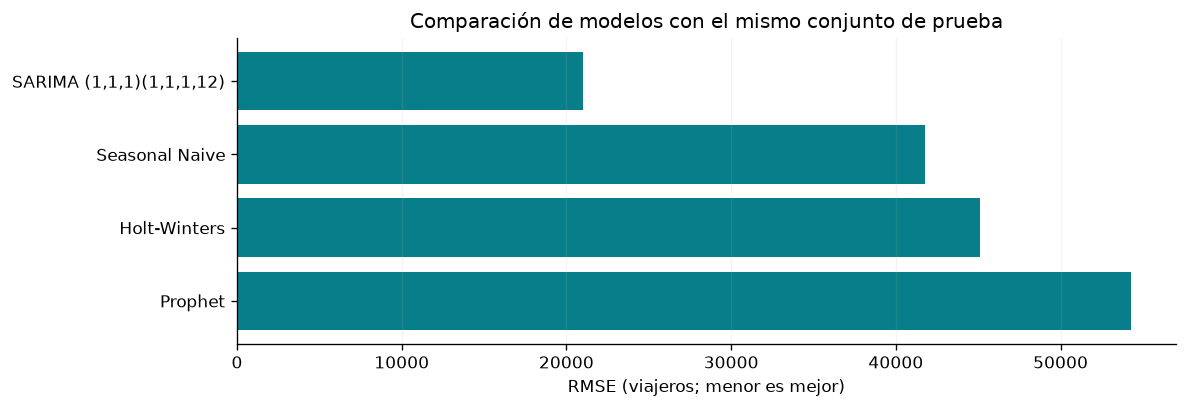

Recomendaciones basadas en la lectura de las series:
1. Planificar personal y capacidad fronteriza para meses de demanda alta.
2. Segmentar campañas entre mercados centroamericanos y norteamericanos.
3. Mantener protocolos de continuidad ante interrupciones como 2020.
4. Actualizar modelos con datos nuevos y vigilar sus errores antes de asignar recursos.


In [8]:
fig,ax=plt.subplots(figsize=(10,3.5));order=metricas.sort_values('RMSE',ascending=True);ax.barh(order['Modelo'],order['RMSE'],color=TEAL);ax.invert_yaxis();ax.set(xlabel='RMSE (viajeros; menor es mejor)',title='Comparación de modelos con el mismo conjunto de prueba');ax.grid(axis='x',alpha=.15);fig.tight_layout();fig.savefig(FIGURES/'final_05_modelos.png');plt.show()
print('Recomendaciones basadas en la lectura de las series:')
print('1. Planificar personal y capacidad fronteriza para meses de demanda alta.')
print('2. Segmentar campañas entre mercados centroamericanos y norteamericanos.')
print('3. Mantener protocolos de continuidad ante interrupciones como 2020.')
print('4. Actualizar modelos con datos nuevos y vigilar sus errores antes de asignar recursos.')

## 8. Guía de uso para la infografía y notas metodológicas

**Narrativa:** titular y KPIs → panorama 2009–2026 → estacionalidad y mercados → cuadrante comparativo → modelos y estimación → recomendaciones.

**Diseño:** azul marino para hechos históricos, turquesa para magnitudes y categorías, naranja para anomalías y estimaciones. Colores de alto contraste; etiquetas directas; sin efectos 3D. Los gráficos guardados pueden integrarse en un lienzo digital ≥1200 × 2400 px y exportarse a PDF de una página 11 × 17 pulgadas.

**Precauciones:** (1) el informe Lab 1 reporta SARIMA como ganador, pero sus métricas difieren de las ejecuciones posteriores; este notebook recalcula la comparación con un corte único; (2) los valores originales pueden ser decimales; (3) no atribuir causalidad a la estacionalidad; (4) el intervalo es una estimación, no certeza; (5) los datos son para fines académicos y no deben publicarse abiertamente.

**Fuente:** Base Migración 2009–junio 2026, INGUAT/IGM, uso académico. **Autores:** Osman de León y Milton Polanco. El documento de explicación debe reflejar el modelo que efectivamente resulte ganador al ejecutar todas las celdas y debe registrar la elección de gráficos, orden y paleta.
